# 05. Q3 첫 주문 경험이 재구매에 영향을 주는가?

- 단위: 고객(`customer_unique_id`). 첫 주문 = 구매 시각이 가장 이른 주문
- **재구매**: 첫 주문 날짜 다음 날 이후(1일 이상 뒤)에 한 주문. 같은 날 추가 주문은 재구매로 보지 않는다(`v_customer_orders.has_repurchase_nextday`)
- **결과 변수**: 첫 주문 후 180일 안에 재구매했는지
- **관찰 기간**: 첫 주문 후 180일을 모두 관찰할 수 있는 고객만 분석한다(첫 주문일 + 180일 ≤ 관찰 종료일)
- 쿼리: `sql/analysis/q3_*.sql` / 차트: `reports/figures/q3_*.png` / 결과 정리: `reports/analysis/q3_first_order_repurchase.md`

재구매율이 약 2%로 매우 낮아서 차이를 **%p(절대 차이)와 상대 비율** 둘 다로 본다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from sqlalchemy import text
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint, proportions_ztest


def find_project_root(start: Path) -> Path:
    """sql/analysis 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "sql" / "analysis").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못함")


ROOT = find_project_root(Path.cwd())
SQL_DIR = ROOT / "sql" / "analysis"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "etl"))
from db import get_engine  # noqa: E402

engine = get_engine()

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

LABEL_KO = {
    "NOT_RECEIVED": "미수령", "WRONG_MISSING": "오배송·누락", "DAMAGED": "파손·불량",
    "NOT_AS_DESCRIBED": "설명 불일치", "LOW_QUALITY": "품질 불만", "SHIPPING_COST": "배송비·수령 불편",
    "DELAY": "배송 지연", "SERVICE": "응대·환불", "OTHER": "기타", "UNCLEAR": "판단 불가", "NO_COMPLAINT": "불만 없음",
    "분류 대상 아님": "분류 대상 아님",
}


def run_sql(name: str) -> pd.DataFrame:
    """sql/analysis의 SQL 파일을 실행해 DataFrame으로 돌려준다(DECIMAL은 float로)."""
    df = pd.read_sql(text((SQL_DIR / name).read_text(encoding="utf-8")), engine)
    for c in df.columns:
        if df[c].dtype == object and df[c].map(lambda v: hasattr(v, "as_tuple")).any():
            df[c] = df[c].astype(float)
    return df


def save(fig, name: str) -> None:
    """차트를 reports/figures에 저장한다."""
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    print(f"저장: reports/figures/{name}")


def compare_rates(k1: int, n1: int, k0: int, n0: int, label1: str, label0: str) -> dict:
    """두 그룹 재구매율의 %p 차이·상대 비율과 95% 신뢰구간, z 검정을 계산해 출력한다."""
    p1, p0 = k1 / n1, k0 / n0
    z, p = proportions_ztest([k1, k0], [n1, n0])
    d_lo, d_hi = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff")
    r_lo, r_hi = confint_proportions_2indep(k1, n1, k0, n0, method="log", compare="ratio")
    print(f"{label1}: {p1:.2%} ({k1:,}/{n1:,})  vs  {label0}: {p0:.2%} ({k0:,}/{n0:,})")
    print(f"  차이 {(p1 - p0) * 100:+.2f}%p, 95% CI [{d_lo * 100:+.2f}, {d_hi * 100:+.2f}]%p")
    print(f"  상대 비율 {p1 / p0:.2f}배 (= {(p1 / p0 - 1):+.0%}), 95% CI [{r_lo:.2f}, {r_hi:.2f}]  /  z = {z:.2f}, p = {p:.3f}")
    return {"비교": f"{label1} vs {label0}", "그룹1 재구매율": p1, "그룹0 재구매율": p0, "차이(%p)": (p1 - p0) * 100,
            "차이 CI 하한": d_lo * 100, "차이 CI 상한": d_hi * 100, "상대 비율": p1 / p0, "비율 CI 하한": r_lo,
            "비율 CI 상한": r_hi, "p값": p}

## 0. 관찰 기간 설정

데이터의 마지막 주문일은 2018-10-17이지만 2018-08-29 이후에는 주문이 거의 없다(9~10월 20건, 배송 완료 0건). 마지막 주문일을 그대로 쓰면 2018년 3~4월 첫 주문 고객은 180일 중 마지막 1~2개월에 재구매가 관찰되지 않는다.
그래서 **관찰 종료일 = 하루 주문이 10건 이상인 마지막 날**로 정하고, 마지막 주문일 기준 결과는 민감도 확인용으로 함께 본다.

In [2]:
window = run_sql("q3_01_observation_window.sql")
display(window.drop(columns=["ord"]).style.format({
    "n_customers_total": "{:,.0f}", "n_included": "{:,.0f}", "n_excluded": "{:,.0f}",
    "repurchase_30d": "{:.2%}", "repurchase_90d": "{:.2%}", "repurchase_180d": "{:.2%}", "repurchase_ever_all_customers": "{:.2%}"}))
main = window.iloc[0]
print(f"분석 대상 고객 {int(main['n_included']):,}명 (제외 {int(main['n_excluded']):,}명), 180일 재구매율 {main['repurchase_180d']:.2%}")

,end_rule,end_date,last_first_purchase_date,n_customers_total,n_included,n_excluded,repurchase_30d,repurchase_90d,repurchase_180d,repurchase_ever_all_customers
0,"실제 수집 종료일 (하루 10건 이상 마지막 날, 분석 기준)",2018-08-29,2018-03-02,"96,096","58,033","38,063",0.66%,1.33%,2.00%,2.24%
1,데이터 마지막 주문일 (민감도 확인용),2018-10-17,2018-04-20,"96,096","68,988","27,108",0.67%,1.32%,1.94%,2.24%


분석 대상 고객 58,033명 (제외 38,063명), 180일 재구매율 2.00%


## 1. 첫 주문 월별 코호트 재구매율

코호트별 30·90·180일 누적 재구매율. 고객 100명 미만 코호트와 일부 날짜만 포함된 마지막 코호트(2018-03, 3월 1~2일)는 차트에서 뺀다.

,cohort_month,n_customers,full_month,repurchase_30d,repurchase_90d,repurchase_180d
0,2016-09,4,1,0.00%,0.00%,0.00%
1,2016-10,321,1,0.31%,0.31%,0.31%
2,2016-12,1,1,100.00%,100.00%,100.00%
3,2017-01,764,1,0.65%,0.92%,1.70%
4,2017-02,"1,752",1,0.57%,0.91%,1.60%
5,2017-03,"2,636",1,0.53%,1.33%,1.78%
6,2017-04,"2,352",1,0.72%,1.32%,2.04%
7,2017-05,"3,596",1,0.92%,1.64%,2.45%
8,2017-06,"3,139",1,0.57%,1.43%,2.33%
9,2017-07,"3,894",1,0.77%,1.31%,2.05%


저장: reports/figures/q3_cohort_repurchase.png


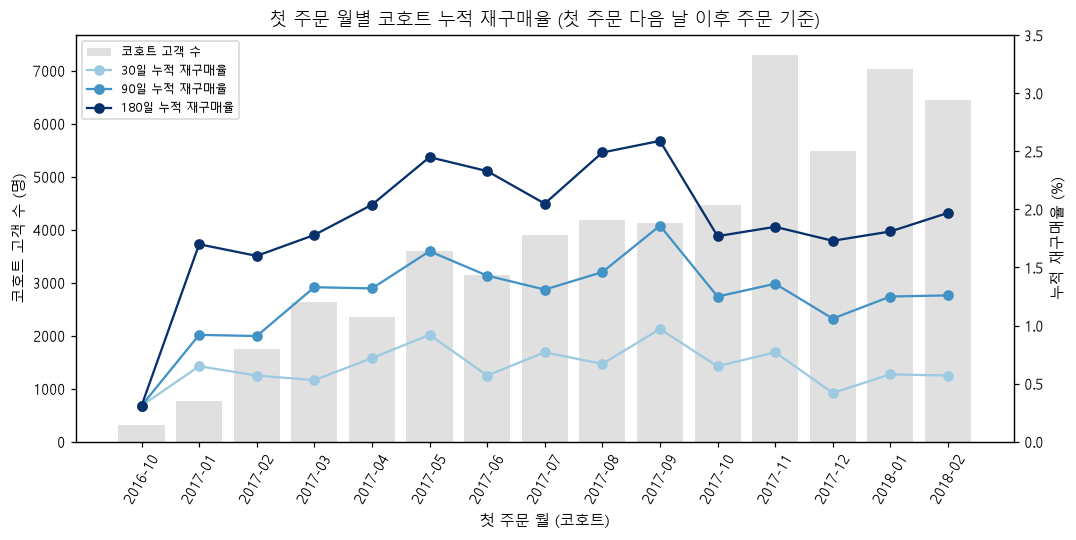

In [3]:
cohort = run_sql("q3_02_cohort_repurchase.sql")
display(cohort.style.format({"n_customers": "{:,.0f}", "repurchase_30d": "{:.2%}", "repurchase_90d": "{:.2%}", "repurchase_180d": "{:.2%}"}))

plot_c = cohort[(cohort["n_customers"] >= 100) & (cohort["full_month"] == 1)].set_index("cohort_month")
fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.bar(plot_c.index, plot_c["n_customers"], color="#e0e0e0", label="코호트 고객 수")
ax1.set_ylabel("코호트 고객 수 (명)")
ax2 = ax1.twinx()
for col, label, color in [("repurchase_30d", "30일", "#9ecae1"), ("repurchase_90d", "90일", "#4292c6"), ("repurchase_180d", "180일", "#08306b")]:
    ax2.plot(plot_c.index, plot_c[col] * 100, marker="o", label=f"{label} 누적 재구매율", color=color)
ax2.set_ylabel("누적 재구매율 (%)")
ax2.set_ylim(0, max(3.5, plot_c["repurchase_180d"].max() * 100 * 1.2))
ax1.set_xlabel("첫 주문 월 (코호트)")
ax1.tick_params(axis="x", rotation=60)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax1.set_title("첫 주문 월별 코호트 누적 재구매율 (첫 주문 다음 날 이후 주문 기준)")
save(fig, "q3_cohort_repurchase.png")
plt.show()

## 2. 첫 주문 경험별 180일 재구매율

지연 여부·지연 구간은 첫 주문이 배송 지표 대상(`exclude_delivery_metrics = 0`)인 경우만 값이 있다. 오차 막대는 Wilson 95% 신뢰구간이다.
재구매 건수가 수십 건인 그룹이 많아 신뢰구간이 넓다는 점에 주의한다.

,dimension,grp_ko,n_customers,n_repurchase_180d,repurchase_180d,CI 하한,CI 상한
0,지연 여부,제때,"52,138","1,064",2.04%,1.92%,2.17%
1,지연 여부,지연,"3,812",61,1.60%,1.25%,2.05%
2,지연 여부,배송 지표 없음,"2,083",38,1.82%,1.33%,2.49%
3,지연 구간,7일 이상 빠름,"45,904",946,2.06%,1.93%,2.19%
4,지연 구간,1~6일 빠름,"5,633",105,1.86%,1.54%,2.25%
5,지연 구간,예상일 당일,601,13,2.16%,1.27%,3.67%
6,지연 구간,1~3일 지연,"1,021",18,1.76%,1.12%,2.77%
7,지연 구간,4~7일 지연,997,14,1.40%,0.84%,2.34%
8,지연 구간,8~14일 지연,853,19,2.23%,1.43%,3.45%
9,지연 구간,15일 이상 지연,941,10,1.06%,0.58%,1.95%


저장: reports/figures/q3_experience_rates.png


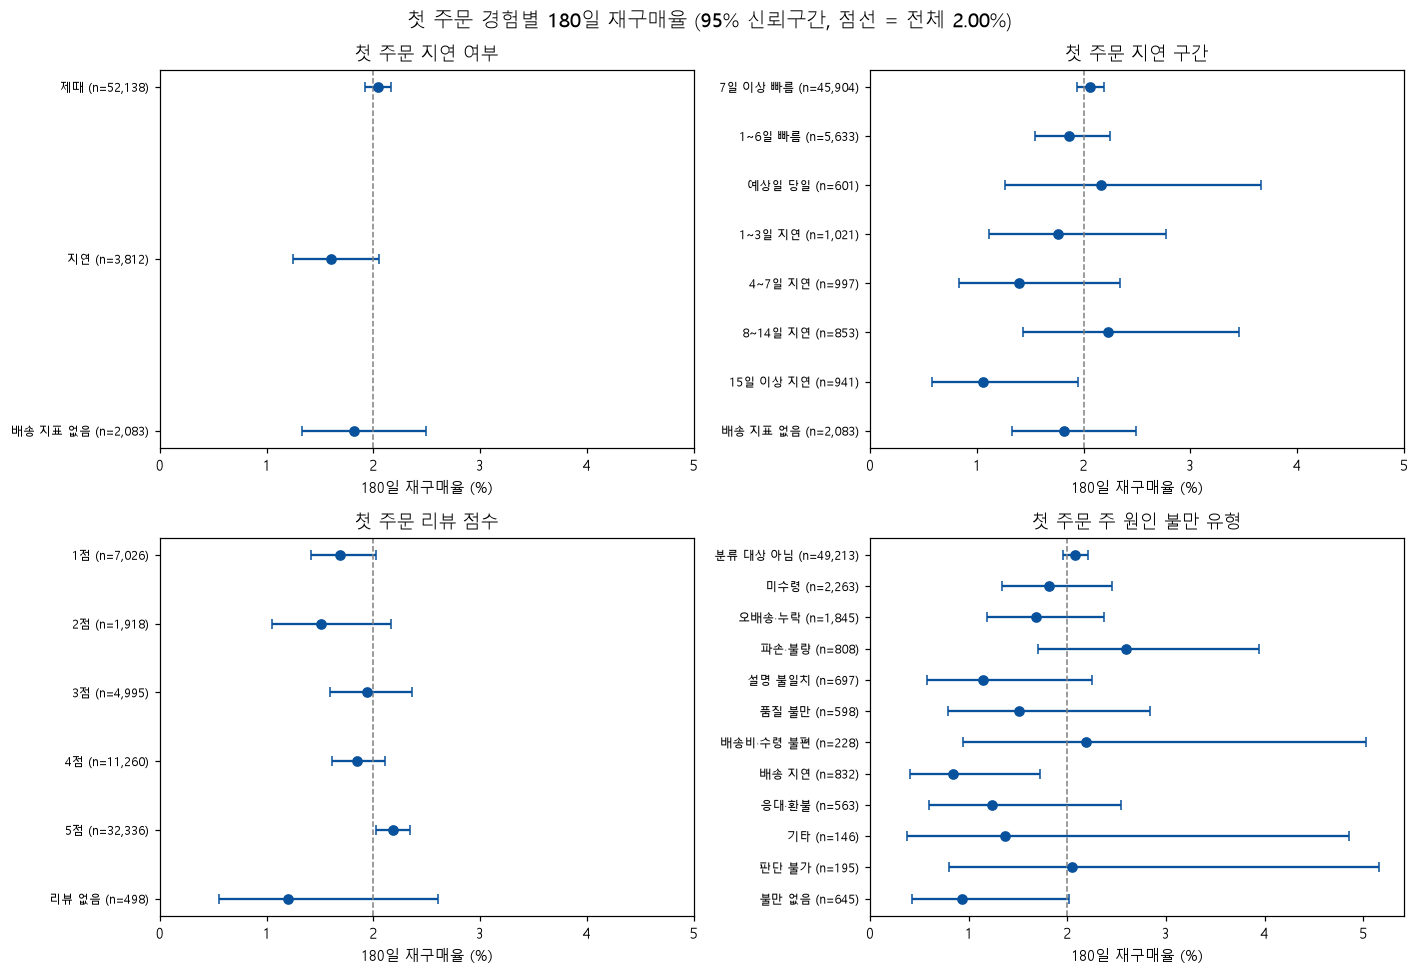

In [4]:
exp = run_sql("q3_03_first_order_experience.sql")
exp["grp_ko"] = np.where(exp["dimension"] == "주 원인 불만 유형", exp["grp"].map(LABEL_KO), exp["grp"])
ci = exp.apply(lambda r: proportion_confint(int(r["n_repurchase_180d"]), int(r["n_customers"]), method="wilson"), axis=1)
exp["CI 하한"] = [c[0] for c in ci]
exp["CI 상한"] = [c[1] for c in ci]
display(exp[["dimension", "grp_ko", "n_customers", "n_repurchase_180d", "repurchase_180d", "CI 하한", "CI 상한"]]
        .style.format({"n_customers": "{:,.0f}", "n_repurchase_180d": "{:,.0f}", "repurchase_180d": "{:.2%}", "CI 하한": "{:.2%}", "CI 상한": "{:.2%}"}))

overall = float(main["repurchase_180d"])
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, dim in zip(axes.flat, ["지연 여부", "지연 구간", "리뷰 점수", "주 원인 불만 유형"]):
    d = exp[exp["dimension"] == dim]
    y = np.arange(len(d))[::-1]
    ax.errorbar(d["repurchase_180d"] * 100, y,
                xerr=[(d["repurchase_180d"] - d["CI 하한"]) * 100, (d["CI 상한"] - d["repurchase_180d"]) * 100],
                fmt="o", color="#08519c", capsize=3)
    ax.axvline(overall * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(y, [f"{g} (n={n:,})" for g, n in zip(d["grp_ko"], d["n_customers"])], fontsize=8)
    ax.set_xlabel("180일 재구매율 (%)")
    ax.set_title(f"첫 주문 {dim}")
    ax.set_xlim(0, max(5, (d["CI 상한"].max() * 100) * 1.05))
fig.suptitle(f"첫 주문 경험별 180일 재구매율 (95% 신뢰구간, 점선 = 전체 {overall:.2%})", fontsize=13)
fig.tight_layout()
save(fig, "q3_experience_rates.png")
plt.show()

## 3. 그룹 간 재구매율 차이: 두 비율 검정

- 첫 주문 지연 vs 제때 (배송 지표 대상 첫 주문만)
- 첫 주문 1~2점 vs 4~5점 (리뷰가 있는 첫 주문만, 3점 제외)

In [5]:
cust = run_sql("q3_04_customer_level.sql")
dl = cust[cust["first_is_late"].notna()]
late_cmp = compare_rates(int(dl.loc[dl["first_is_late"] == 1, "repurchase_180d"].sum()), int((dl["first_is_late"] == 1).sum()),
                         int(dl.loc[dl["first_is_late"] == 0, "repurchase_180d"].sum()), int((dl["first_is_late"] == 0).sum()),
                         "첫 주문 지연", "첫 주문 제때")
print()
low = cust[cust["first_review_score"] <= 2]
high = cust[cust["first_review_score"] >= 4]
score_cmp = compare_rates(int(low["repurchase_180d"].sum()), len(low), int(high["repurchase_180d"].sum()), len(high),
                          "첫 주문 1~2점", "첫 주문 4~5점")
display(pd.DataFrame([late_cmp, score_cmp]).round(4))

첫 주문 지연: 1.60% (61/3,812)  vs  첫 주문 제때: 2.04% (1,064/52,138)
  차이 -0.44%p, 95% CI [-0.81, +0.02]%p
  상대 비율 0.78배 (= -22%), 95% CI [0.61, 1.01]  /  z = -1.87, p = 0.061

첫 주문 1~2점: 1.65% (148/8,944)  vs  첫 주문 4~5점: 2.09% (912/43,596)
  차이 -0.44%p, 95% CI [-0.72, -0.12]%p
  상대 비율 0.79배 (= -21%), 95% CI [0.67, 0.94]  /  z = -2.68, p = 0.007


,비교,그룹1 재구매율,그룹0 재구매율,차이(%p),차이 CI 하한,차이 CI 상한,상대 비율,비율 CI 하한,비율 CI 상한,p값
0,첫 주문 지연 vs 첫 주문 제때,0.0160,0.0204,-0.4405,-0.8144,0.0245,0.7841,0.6071,1.0128,0.0614
1,첫 주문 1~2점 vs 첫 주문 4~5점,0.0165,0.0209,-0.4372,-0.7182,-0.1231,0.7910,0.6659,0.9396,0.0074


## 4. 첫 주문 후 일수별 누적 재구매 곡선

첫 주문 후 d일까지 재구매한 고객 비율. 분석 대상 고객은 모두 180일을 관찰할 수 있으므로 단순 누적 비율로 계산한다.

저장: reports/figures/q3_cumulative_curve.png


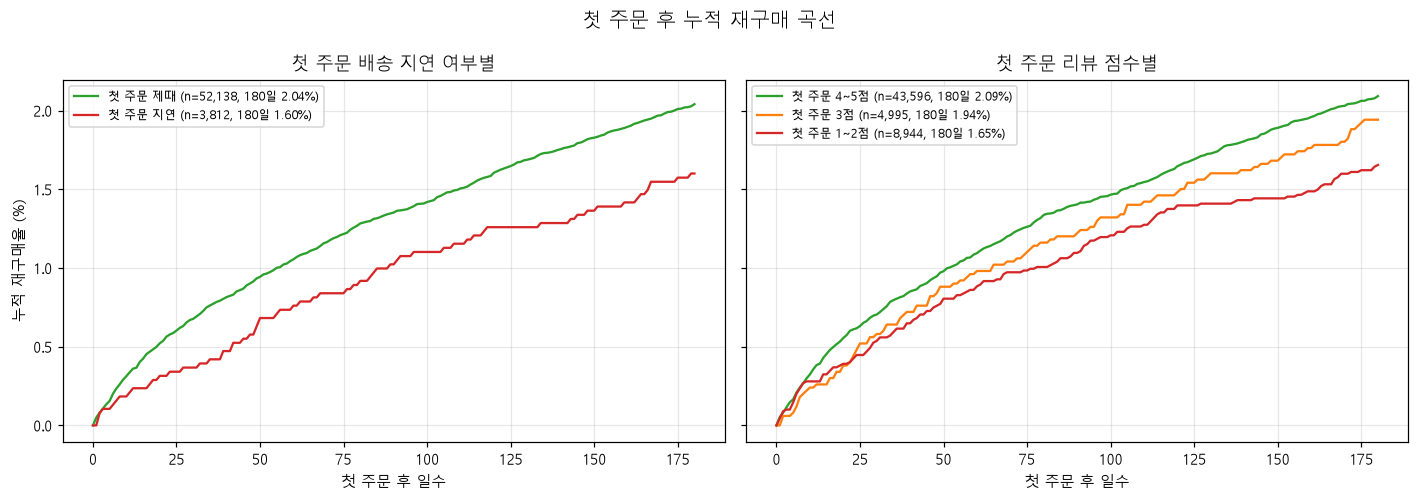

In [6]:
days = np.arange(0, 181)


def cumulative(df: pd.DataFrame) -> np.ndarray:
    """첫 주문 후 d일(0~180)까지 재구매한 고객 비율(%)."""
    rep = df["days_to_first_repurchase"].to_numpy(dtype=float)
    return np.array([(rep <= d).sum() for d in days]) / len(df) * 100


fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, groups, title in [
    (axes[0], [("첫 주문 제때", dl[dl["first_is_late"] == 0], "#2ca02c"), ("첫 주문 지연", dl[dl["first_is_late"] == 1], "#d62728")],
     "첫 주문 배송 지연 여부별"),
    (axes[1], [("첫 주문 4~5점", high, "#2ca02c"), ("첫 주문 3점", cust[cust["first_review_score"] == 3], "#ff7f0e"),
               ("첫 주문 1~2점", low, "#d62728")], "첫 주문 리뷰 점수별"),
]:
    for label, df, color in groups:
        curve = cumulative(df)
        ax.plot(days, curve, label=f"{label} (n={len(df):,}, 180일 {curve[-1]:.2f}%)", color=color)
    ax.set_xlabel("첫 주문 후 일수")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("누적 재구매율 (%)")
fig.suptitle("첫 주문 후 누적 재구매 곡선", fontsize=13)
fig.tight_layout()
save(fig, "q3_cumulative_curve.png")
plt.show()

## 5. 로지스틱 회귀: 180일 재구매

- 표본: 첫 주문이 배송 지표 대상이고 리뷰·상품 금액이 있는 고객
- 통제변수: 첫 주문 상품 금액(100 BRL 단위), 배송비, 상품 수, 판매자 수, 고객 주(더미, 기준 SP. 고객 1,000명 미만인 주는 '기타 주'로 묶음 — 재구매가 드물어 작은 주는 추정이 불안정함)
- **모형 A**: 첫 주문 지연 여부만 / **모형 B**: 지연 여부 + 첫 주문 1~2점 여부
- 지연은 저평점의 강한 원인이라(Q2) 모형 B에서는 지연의 효과 일부가 저평점으로 넘어간다. 두 모형을 함께 본다.
- 오즈비 = exp(계수). 재구매율이 2% 안팎으로 낮아서 오즈비는 상대 위험(재구매율 비)과 거의 같게 읽어도 된다.

In [7]:
mdf = cust[cust["first_is_late"].notna() & cust["first_review_score"].notna() & cust["items_value"].notna()].copy()
mdf["first_is_late"] = mdf["first_is_late"].astype(int)
mdf["first_low_score"] = (mdf["first_review_score"] <= 2).astype(int)
mdf["items_100brl"] = mdf["items_value"].astype(float) / 100
mdf["freight_value"] = mdf["freight_value"].astype(float)
state_n = mdf["customer_state"].value_counts()
mdf["state_grp"] = np.where(mdf["customer_state"].map(state_n) >= 1000, mdf["customer_state"], "기타 주")
print(f"회귀 표본 {len(mdf):,}명, 재구매 {int(mdf['repurchase_180d'].sum()):,}명 ({mdf['repurchase_180d'].mean():.2%})")
print("주 그룹:", sorted(mdf["state_grp"].unique()))

controls = "items_100brl + freight_value + n_items + n_sellers + C(state_grp, Treatment('SP'))"
mA = smf.logit(f"repurchase_180d ~ first_is_late + {controls}", data=mdf).fit(disp=False, maxiter=200)
mB = smf.logit(f"repurchase_180d ~ first_is_late + first_low_score + {controls}", data=mdf).fit(disp=False, maxiter=200)

rename = {"first_is_late": "첫 주문 지연", "first_low_score": "첫 주문 1~2점", "items_100brl": "상품 금액(100 BRL당)",
          "freight_value": "배송비(BRL당)", "n_items": "상품 수(1개당)", "n_sellers": "판매자 수(1명당)"}


def odds_table(model) -> pd.DataFrame:
    """주요 변수의 오즈비, 95% 신뢰구간, p값 표."""
    ci = model.conf_int()
    out = pd.DataFrame({"오즈비": np.exp(model.params), "CI 하한": np.exp(ci[0]), "CI 상한": np.exp(ci[1]), "p값": model.pvalues})
    return out.loc[[k for k in rename if k in out.index]].rename(index=rename)


def ame_table(model, names: list[str]) -> pd.DataFrame:
    """평균 한계효과(%p)와 95% 신뢰구간 표. 열 순서: dy/dx, 표준오차, z, p, CI 하한, CI 상한."""
    frame = model.get_margeff(at="overall").summary_frame()
    rows = {rename[n]: frame.loc[n] for n in names}
    return pd.DataFrame({k: {"AME(%p)": v.iloc[0] * 100, "CI 하한(%p)": v.iloc[-2] * 100, "CI 상한(%p)": v.iloc[-1] * 100}
                         for k, v in rows.items()}).T


for name, model, keys in [("모형 A", mA, ["first_is_late"]), ("모형 B", mB, ["first_is_late", "first_low_score"])]:
    print(f"\n{name}: n = {int(model.nobs):,}, McFadden 의사 R² = {model.prsquared:.4f}")
    display(odds_table(model).round(3))
    display(ame_table(model, keys).round(3))

회귀 표본 55,533명, 재구매 1,120명 (2.02%)
주 그룹: ['BA', 'DF', 'ES', 'GO', 'MG', 'PR', 'RJ', 'RS', 'SC', 'SP', '기타 주']



모형 A: n = 55,533, McFadden 의사 R² = 0.0043


,오즈비,CI 하한,CI 상한,p값
첫 주문 지연,0.816,0.627,1.062,0.130
상품 금액(100 BRL당),0.959,0.922,0.998,0.037
배송비(BRL당),1.002,0.999,1.005,0.166
상품 수(1개당),1.179,1.082,1.286,0.000
판매자 수(1명당),1.064,0.671,1.685,0.793


,AME(%p),CI 하한(%p),CI 상한(%p)
첫 주문 지연,-0.401,-0.92,0.119



모형 B: n = 55,533, McFadden 의사 R² = 0.0047


,오즈비,CI 하한,CI 상한,p값
첫 주문 지연,0.916,0.689,1.217,0.545
첫 주문 1~2점,0.807,0.656,0.992,0.042
상품 금액(100 BRL당),0.959,0.922,0.998,0.038
배송비(BRL당),1.002,0.999,1.005,0.152
상품 수(1개당),1.190,1.092,1.298,0.000
판매자 수(1명당),1.126,0.709,1.788,0.614


,AME(%p),CI 하한(%p),CI 상한(%p)
첫 주문 지연,-0.173,-0.734,0.388
첫 주문 1~2점,-0.424,-0.832,-0.015


### 오즈비 그래프

점선(1)보다 왼쪽이면 재구매 가능성이 낮다. 신뢰구간이 1을 포함하면 이 표본에서는 효과를 확신할 수 없다는 뜻이다.

저장: reports/figures/q3_odds_ratios.png


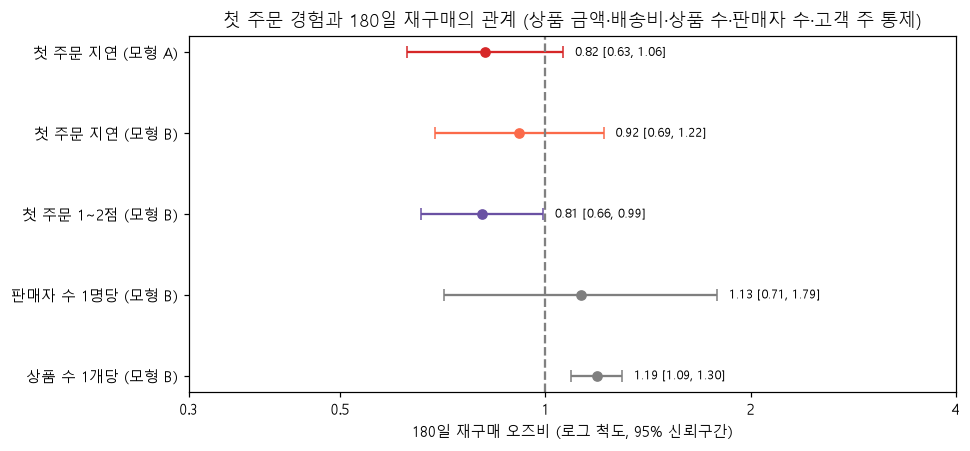

In [8]:
tA, tB = odds_table(mA), odds_table(mB)
rows = [("첫 주문 지연 (모형 A)", tA.loc["첫 주문 지연"], "#d62728"),
        ("첫 주문 지연 (모형 B)", tB.loc["첫 주문 지연"], "#fb6a4a"),
        ("첫 주문 1~2점 (모형 B)", tB.loc["첫 주문 1~2점"], "#6a51a3"),
        ("판매자 수 1명당 (모형 B)", tB.loc["판매자 수(1명당)"], "#7f7f7f"),
        ("상품 수 1개당 (모형 B)", tB.loc["상품 수(1개당)"], "#7f7f7f")][::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (label, r, color) in enumerate(rows):
    ax.errorbar(r["오즈비"], i, xerr=[[r["오즈비"] - r["CI 하한"]], [r["CI 상한"] - r["오즈비"]]], fmt="o", color=color, capsize=4)
    ax.text(r["CI 상한"] * 1.04, i, f"{r['오즈비']:.2f} [{r['CI 하한']:.2f}, {r['CI 상한']:.2f}]", va="center", fontsize=8)
ax.axvline(1, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set_xlabel("180일 재구매 오즈비 (로그 척도, 95% 신뢰구간)")
ax.set_title("첫 주문 경험과 180일 재구매의 관계 (상품 금액·배송비·상품 수·판매자 수·고객 주 통제)")
ax.set_xlim(0.3, 4)
# 로그 축 기본 눈금(10^-1 등 수식 글꼴)은 한글 폰트에서 마이너스 기호가 깨지므로 일반 숫자로 지정
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks([0.3, 0.5, 1, 2, 4], ["0.3", "0.5", "1", "2", "4"])
save(fig, "q3_odds_ratios.png")
plt.show()

## 정리

핵심 발견, 관찰 기간 설정 방법, 해석 주의점은 `reports/analysis/q3_first_order_repurchase.md`에 정리했다.